In [1]:
%pip install pandas numpy matplotlib seaborn mysql-connector-python sqlalchemy reportlab

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\ASUS\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import mysql.connector
from sqlalchemy import create_engine, URL

import os
from datetime import datetime

from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image,
    PageBreak
)

from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
os.makedirs("../Reports", exist_ok=True)

os.makedirs("../Reports/Charts", exist_ok=True)

print("Report folders created successfully!")

Report folders created successfully!


In [4]:
engine_url = URL.create(
    drivername="mysql+mysqlconnector",
    username="root",
    password="Rushi@25",
    host="localhost",
    port=3306,
    database="creditcardfrauddb"
)

engine = create_engine(engine_url)

print("MySQL connection created successfully!")

MySQL connection created successfully!


In [5]:
query = """
SELECT
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraud_transactions,
    COUNT(DISTINCT customer_id) AS total_customers,
    COUNT(DISTINCT merchant) AS total_merchants
FROM credit_card_transactions;
"""

report_summary = pd.read_sql_query(query, engine)

report_summary

,total_transactions,fraud_transactions,total_customers,total_merchants
0,500000,2894.0,982,693


In [6]:
query = """
SELECT
    COUNT(*) AS total_transactions,

    SUM(is_fraud) AS fraud_transactions,

    COUNT(*) - SUM(is_fraud) AS non_fraud_transactions,

    ROUND(
        SUM(is_fraud) * 100.0 / COUNT(*), 2
    ) AS fraud_rate,

    ROUND(SUM(transaction_amount), 2) AS total_transaction_amount,

    ROUND(AVG(transaction_amount), 2) AS average_transaction_amount,

    ROUND(
        SUM(CASE
            WHEN is_fraud = 1 THEN transaction_amount
            ELSE 0
        END), 2
    ) AS fraudulent_transaction_amount

FROM credit_card_transactions;
"""

kpi_data = pd.read_sql_query(query, engine)

kpi_data

,total_transactions,fraud_transactions,non_fraud_transactions,fraud_rate,total_transaction_amount,average_transaction_amount,fraudulent_transaction_amount
0,500000,2894.0,497106.0,0.58,35395944.09,70.79,1581912.11


In [7]:
kpi = kpi_data.iloc[0]

print("CREDIT CARD FRAUD ANALYSIS – KEY METRICS")
print("-" * 45)

print(f"Total Transactions: {kpi['total_transactions']:,}")
print(f"Fraud Transactions: {kpi['fraud_transactions']:,}")
print(f"Non-Fraud Transactions: {kpi['non_fraud_transactions']:,}")
print(f"Fraud Rate: {kpi['fraud_rate']}%")

print(f"Total Transaction Amount: ₹{kpi['total_transaction_amount']:,.2f}")
print(f"Average Transaction Amount: ₹{kpi['average_transaction_amount']:,.2f}")
print(f"Fraudulent Transaction Amount: ₹{kpi['fraudulent_transaction_amount']:,.2f}")

CREDIT CARD FRAUD ANALYSIS – KEY METRICS
---------------------------------------------
Total Transactions: 500,000.0
Fraud Transactions: 2,894.0
Non-Fraud Transactions: 497,106.0
Fraud Rate: 0.58%
Total Transaction Amount: ₹35,395,944.09
Average Transaction Amount: ₹70.79
Fraudulent Transaction Amount: ₹1,581,912.11


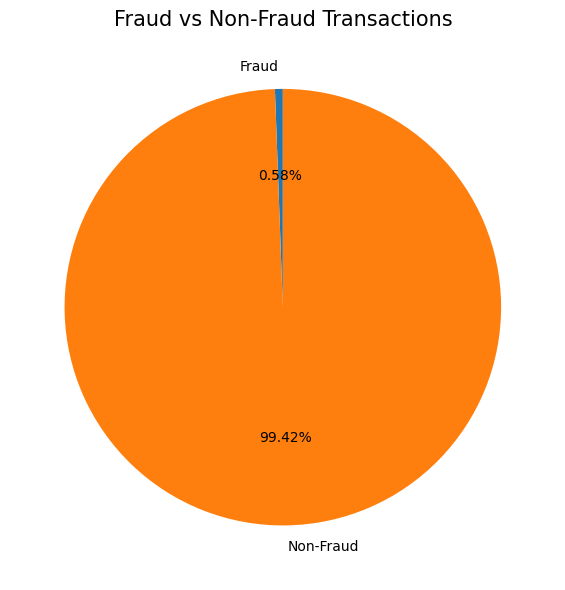

In [8]:
fraud_counts = [
    int(kpi['fraud_transactions']),
    int(kpi['non_fraud_transactions'])
]

labels = ['Fraud', 'Non-Fraud']

plt.figure(figsize=(8, 6))

plt.pie(
    fraud_counts,
    labels=labels,
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Fraud vs Non-Fraud Transactions',
          fontsize=15)

plt.tight_layout()

plt.savefig(
    '../Reports/Charts/fraud_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

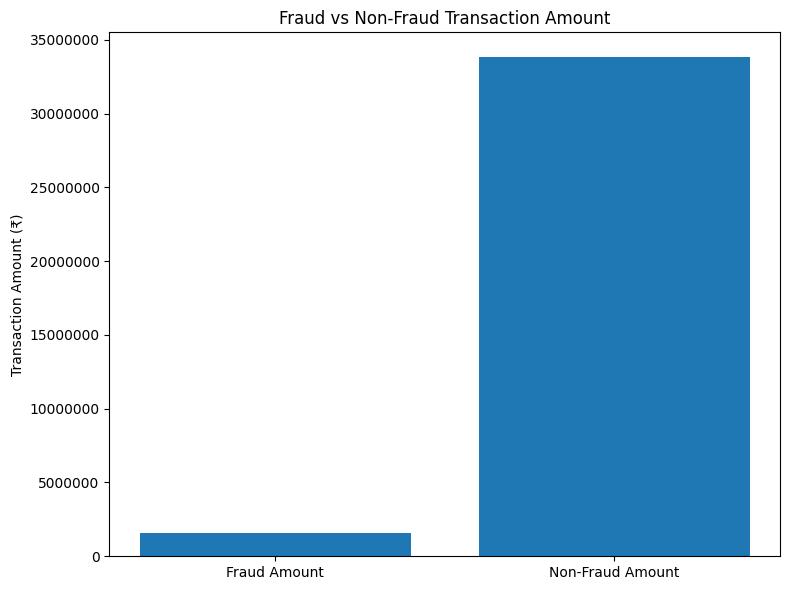

In [9]:
fraud_amounts = [
    float(kpi['fraudulent_transaction_amount']),
    float(kpi['total_transaction_amount'] -
          kpi['fraudulent_transaction_amount'])
]

labels = ['Fraud Amount', 'Non-Fraud Amount']

plt.figure(figsize=(8, 6))

plt.bar(labels, fraud_amounts)

plt.title('Fraud vs Non-Fraud Transaction Amount')

plt.ylabel('Transaction Amount (₹)')

plt.ticklabel_format(
    style='plain',
    axis='y'
)

plt.tight_layout()

plt.savefig(
    '../Reports/Charts/fraud_amount_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

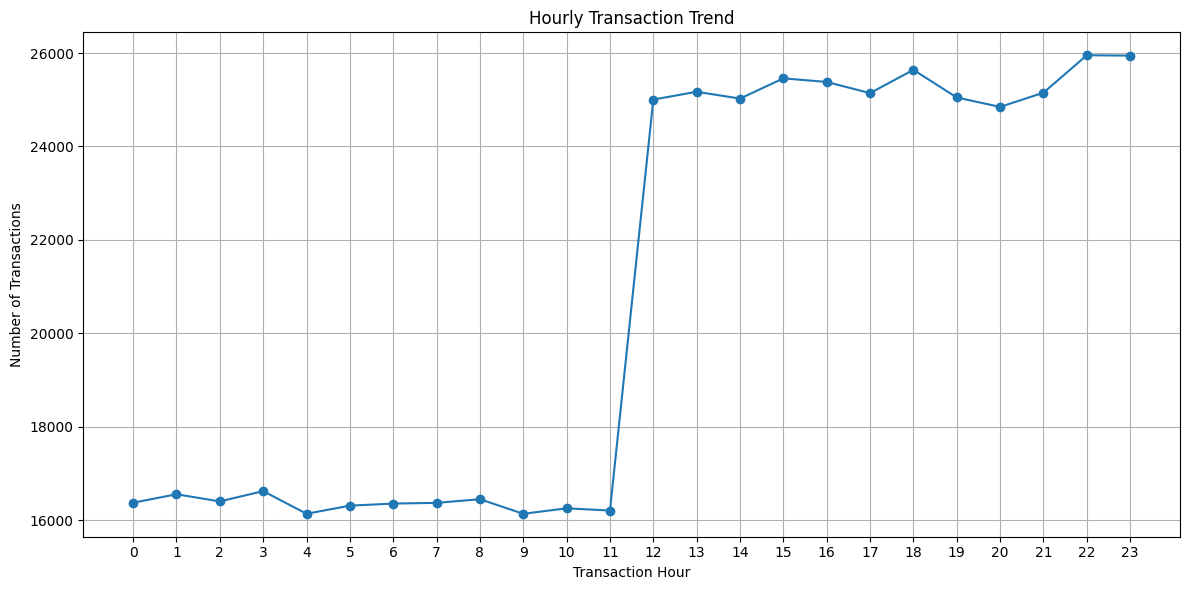

In [10]:
query = """
SELECT
    transaction_hour,
    COUNT(*) AS total_transactions,
    SUM(is_fraud) AS fraud_transactions
FROM credit_card_transactions
GROUP BY transaction_hour
ORDER BY transaction_hour;
"""

hourly_data = pd.read_sql_query(query, engine)

plt.figure(figsize=(12, 6))

plt.plot(
    hourly_data['transaction_hour'],
    hourly_data['total_transactions'],
    marker='o'
)

plt.title('Hourly Transaction Trend')
plt.xlabel('Transaction Hour')
plt.ylabel('Number of Transactions')
plt.xticks(range(24))
plt.grid(True)

plt.tight_layout()

plt.savefig(
    '../Reports/Charts/hourly_transaction_trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

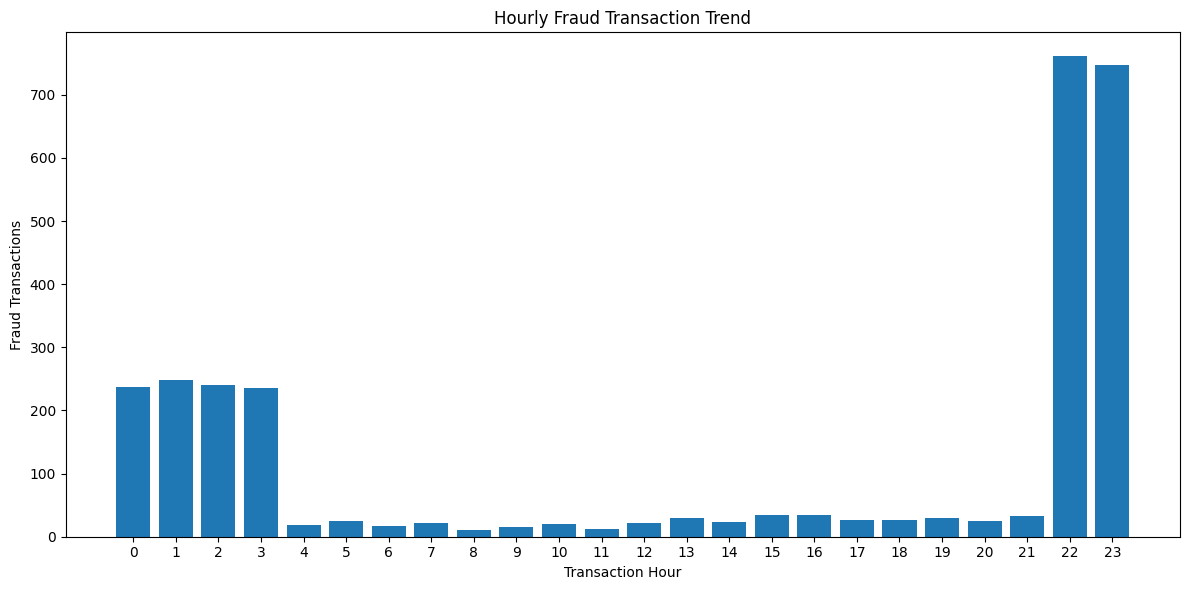

In [11]:
plt.figure(figsize=(12, 6))

plt.bar(
    hourly_data['transaction_hour'],
    hourly_data['fraud_transactions']
)

plt.title('Hourly Fraud Transaction Trend')
plt.xlabel('Transaction Hour')
plt.ylabel('Fraud Transactions')
plt.xticks(range(24))

plt.tight_layout()

plt.savefig(
    '../Reports/Charts/hourly_fraud_trend.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

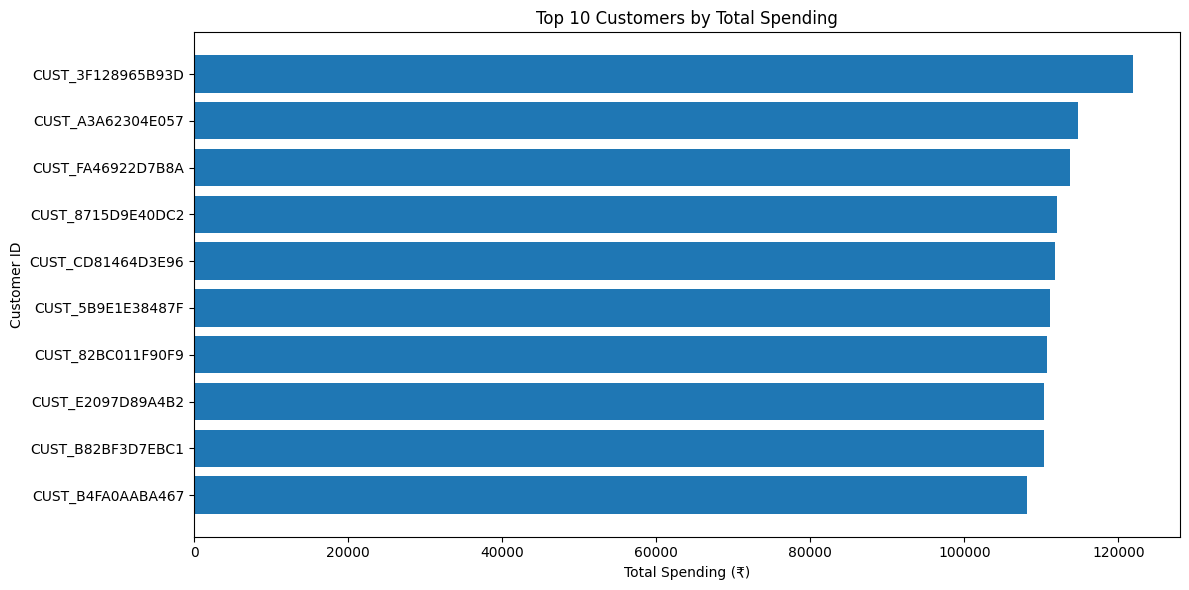

In [12]:
query = """
SELECT
    customer_id,
    ROUND(SUM(transaction_amount), 2) AS total_spending
FROM credit_card_transactions
GROUP BY customer_id
ORDER BY total_spending DESC
LIMIT 10;
"""

top_customers = pd.read_sql_query(query, engine)

plt.figure(figsize=(12, 6))

plt.barh(
    top_customers['customer_id'],
    top_customers['total_spending']
)

plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Total Spending (₹)')
plt.ylabel('Customer ID')
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig('../Reports/Charts/top_10_customers.png',
            dpi=300, bbox_inches='tight')

plt.show()

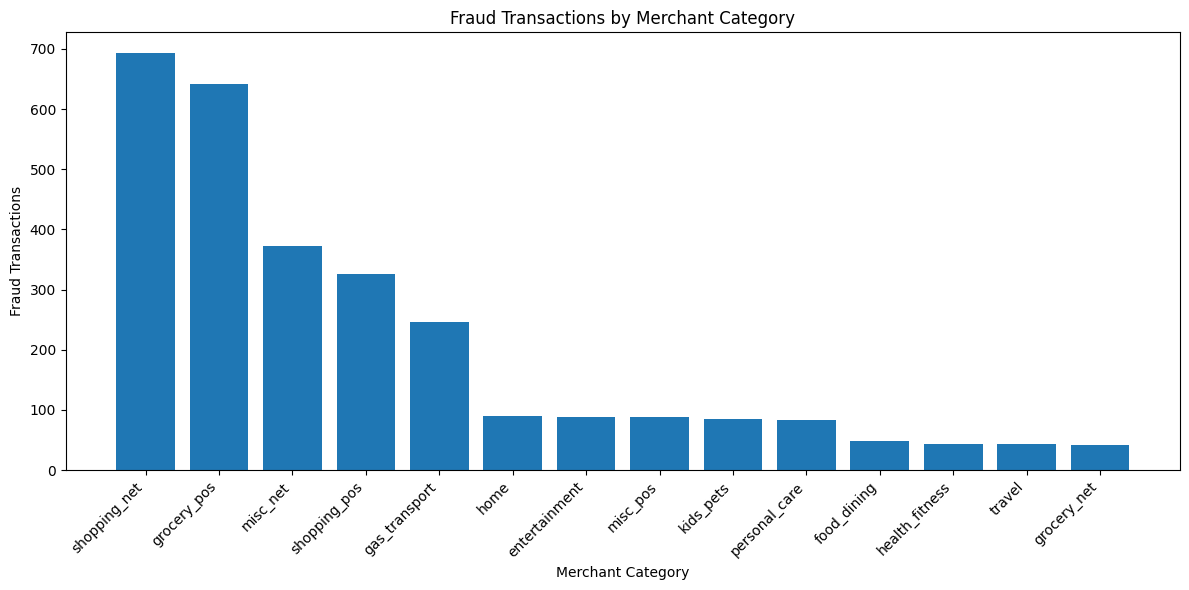

In [13]:
query = """
SELECT
    merchant_category,
    SUM(is_fraud) AS fraud_transactions
FROM credit_card_transactions
GROUP BY merchant_category
ORDER BY fraud_transactions DESC;
"""

category_data = pd.read_sql_query(query, engine)

plt.figure(figsize=(12, 6))

plt.bar(
    category_data['merchant_category'],
    category_data['fraud_transactions']
)

plt.title('Fraud Transactions by Merchant Category')
plt.xlabel('Merchant Category')
plt.ylabel('Fraud Transactions')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.savefig('../Reports/Charts/category_fraud.png',
            dpi=300, bbox_inches='tight')

plt.show()

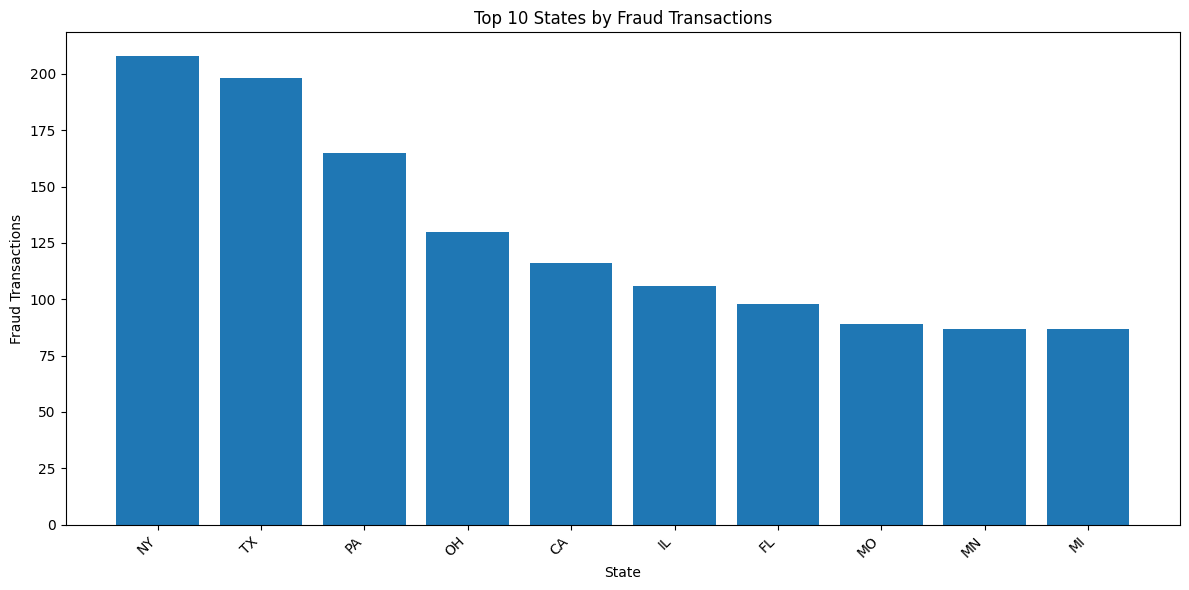

In [14]:
query = """
SELECT
    state,
    SUM(is_fraud) AS fraud_transactions
FROM credit_card_transactions
GROUP BY state
ORDER BY fraud_transactions DESC
LIMIT 10;
"""

state_data = pd.read_sql_query(query, engine)

plt.figure(figsize=(12, 6))

plt.bar(
    state_data['state'],
    state_data['fraud_transactions']
)

plt.title('Top 10 States by Fraud Transactions')
plt.xlabel('State')
plt.ylabel('Fraud Transactions')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()

plt.savefig('../Reports/Charts/state_fraud.png',
            dpi=300, bbox_inches='tight')

plt.show()

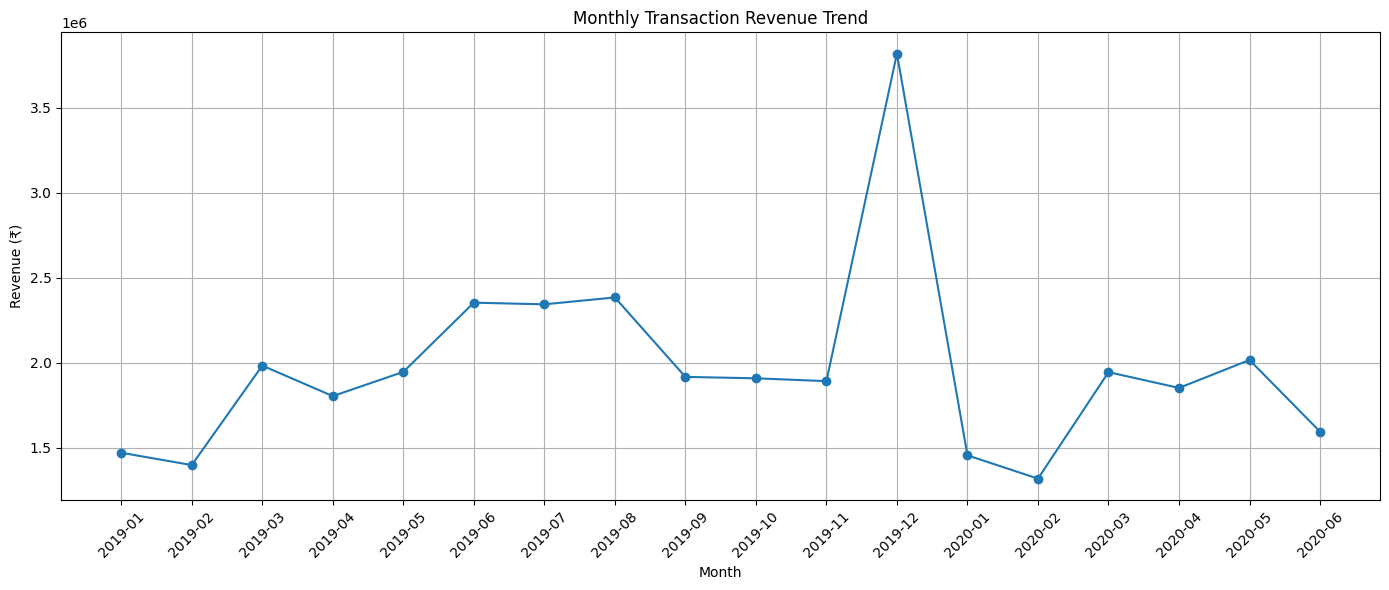

In [15]:
query = """
SELECT
    DATE_FORMAT(transaction_datetime, '%Y-%m') AS transaction_month,
    ROUND(SUM(transaction_amount), 2) AS total_revenue
FROM credit_card_transactions
GROUP BY DATE_FORMAT(transaction_datetime, '%Y-%m')
ORDER BY transaction_month;
"""

monthly_data = pd.read_sql_query(query, engine)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_data['transaction_month'],
    monthly_data['total_revenue'],
    marker='o'
)

plt.title('Monthly Transaction Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()

plt.savefig('../Reports/Charts/monthly_revenue.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [16]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image,
    PageBreak
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch

pdf_path = "../Reports/Credit_Card_Fraud_Analysis_Report.pdf"

doc = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()

story = []

print("PDF report configuration completed!")

PDF report configuration completed!


In [17]:
title_style = ParagraphStyle(
    'CustomTitle',
    parent=styles['Title'],
    fontSize=24,
    alignment=TA_CENTER,
    textColor=colors.darkblue,
    spaceAfter=20
)

subtitle_style = ParagraphStyle(
    'Subtitle',
    parent=styles['Normal'],
    fontSize=13,
    alignment=TA_CENTER,
    leading=20
)

story.append(Spacer(1, 2 * inch))

story.append(
    Paragraph(
        "CREDIT CARD TRANSACTION<br/>FRAUD ANALYSIS",
        title_style
    )
)

story.append(Spacer(1, 0.4 * inch))

story.append(
    Paragraph(
        "Data Analytics Project Report",
        subtitle_style
    )
)

story.append(Spacer(1, 1 * inch))

story.append(
    Paragraph(
        "Tools Used: Python | MySQL | Pandas | Matplotlib | Power BI",
        subtitle_style
    )
)

story.append(Spacer(1, 0.5 * inch))

story.append(
    Paragraph(
        "Dataset: 500,000 Transactions",
        subtitle_style
    )
)

story.append(
    Paragraph(
        f"Report Generated: {datetime.now().strftime('%d-%m-%Y')}",
        subtitle_style
    )
)

story.append(PageBreak())

print("Title page created successfully!")

Title page created successfully!


In [18]:
story.append(
    Paragraph("1. Project Overview", styles['Heading1'])
)

overview = """
This project analyses credit card transactions to identify fraudulent
transaction patterns, understand customer spending behaviour and examine
fraud activity across merchants, locations and time periods.

The analysis uses Python for data processing and visualization,
MySQL for database storage and SQL analysis, and Power BI for
interactive business reporting.
"""

story.append(Paragraph(overview, styles['BodyText']))

story.append(Spacer(1, 15))

In [19]:
kpi_table_data = [
    ["Key Performance Indicator", "Value"],

    ["Total Transactions",
     f"{int(kpi['total_transactions']):,}"],

    ["Fraud Transactions",
     f"{int(kpi['fraud_transactions']):,}"],

    ["Non-Fraud Transactions",
     f"{int(kpi['non_fraud_transactions']):,}"],

    ["Fraud Rate",
     f"{kpi['fraud_rate']}%"],

    ["Total Transaction Amount",
     f"Rs. {kpi['total_transaction_amount']:,.2f}"],

    ["Average Transaction Amount",
     f"Rs. {kpi['average_transaction_amount']:,.2f}"],

    ["Fraudulent Transaction Amount",
     f"Rs. {kpi['fraudulent_transaction_amount']:,.2f}"]
]

kpi_table = Table(
    kpi_table_data,
    colWidths=[260, 200]
)

kpi_table.setStyle(TableStyle([
    ('BACKGROUND', (0, 0), (-1, 0), colors.darkblue),
    ('TEXTCOLOR', (0, 0), (-1, 0), colors.white),
    ('GRID', (0, 0), (-1, -1), 0.5, colors.grey),
    ('PADDING', (0, 0), (-1, -1), 8),
    ('ALIGN', (1, 1), (-1, -1), 'RIGHT'),
    ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold')
]))

story.append(
    Paragraph("2. Key Performance Indicators", styles['Heading1'])
)

story.append(kpi_table)

story.append(Spacer(1, 20))

In [20]:
chart_sections = [
    (
        "3. Fraud vs Non-Fraud Distribution",
        "fraud_distribution.png",
        "The dataset contains 2,894 fraudulent transactions out of 500,000 transactions."
    ),
    (
        "4. Fraud vs Non-Fraud Transaction Amount",
        "fraud_amount_comparison.png",
        "This chart compares the financial value of fraudulent and non-fraudulent transactions."
    ),
    (
        "5. Hourly Transaction Trend",
        "hourly_transaction_trend.png",
        "This chart shows how transaction volumes vary throughout the day."
    ),
    (
        "6. Hourly Fraud Trend",
        "hourly_fraud_trend.png",
        "This chart highlights the distribution of fraudulent transactions across different hours."
    ),
    (
        "7. Top 10 Customers by Spending",
        "top_10_customers.png",
        "This chart identifies the customers with the highest total transaction spending."
    ),
    (
        "8. Fraud by Merchant Category",
        "category_fraud.png",
        "This chart compares fraudulent transaction counts across merchant categories."
    ),
    (
        "9. State-wise Fraud Transactions",
        "state_fraud.png",
        "This chart presents the ten states with the highest fraudulent transaction counts."
    ),
    (
        "10. Monthly Transaction Revenue",
        "monthly_revenue.png",
        "This chart illustrates monthly transaction revenue trends."
    )
]

for heading, filename, description in chart_sections:

    story.append(PageBreak())

    story.append(
        Paragraph(heading, styles['Heading1'])
    )

    story.append(Spacer(1, 12))

    chart_path = f"../Reports/Charts/{filename}"

    story.append(
        Image(chart_path, width=460, height=270)
    )

    story.append(Spacer(1, 12))

    story.append(
        Paragraph(description, styles['BodyText'])
    )

print("All 8 charts added to the PDF report!")

All 8 charts added to the PDF report!


In [21]:
story.append(PageBreak())

story.append(
    Paragraph("12. Business Recommendations", styles['Heading1'])
)

recommendations = [
    "Monitor transactions during hours with higher observed fraud activity.",
    "Apply additional monitoring to merchant categories with higher fraud rates.",
    "Investigate customers associated with repeated fraudulent transactions.",
    "Review unusually high-value transactions for potential suspicious activity.",
    "Monitor geographical transaction patterns and investigate unusual activity.",
    "Use continuous fraud monitoring and periodic analysis to identify changing patterns."
]

for recommendation in recommendations:
    story.append(
        Paragraph("• " + recommendation, styles['BodyText'])
    )
    story.append(Spacer(1, 10))

print("Business recommendations added successfully!")

Business recommendations added successfully!


In [22]:
doc.build(story)

print("PDF REPORT GENERATED SUCCESSFULLY!")
print("Location:", os.path.abspath(pdf_path))

PDF REPORT GENERATED SUCCESSFULLY!
Location: c:\Users\ASUS\Desktop\DA project\Reports\Credit_Card_Fraud_Analysis_Report.pdf
